In [1]:
import hashlib
import os
import platform
import uuid

# 修改为自己的学号
STUDENT_ID = 20244080201

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]

RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"

print(f"[学号]       {STUDENT_ID}")
print(f"[机器指纹]   {MACHINE_FP}")
print(f"[RUN_ID]     {RUN_ID}")

[Conda 环境] pythonlab
[学号]       20244080201
[机器指纹]   298e39f064658df4
[RUN_ID]     20244080201-298e39f064658df4


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [3]:
def wigner_density(x):
    if abs(x) <= 2:
        return float(np.sqrt(4 - x**2) / (2 * np.pi))
    else:
        return 0.0

In [4]:
print("x=0：", wigner_density(0))
print("x=1：", wigner_density(1))
print("x=2：", wigner_density(2))
print("x=3：", wigner_density(3))

print("NumPy整数测试：", wigner_density(np.int64(1)))
print("NumPy浮点数测试：", wigner_density(np.float64(1.5)))

x=0： 0.3183098861837907
x=1： 0.27566444771089604
x=2： 0.0
x=3： 0.0
NumPy整数测试： 0.27566444771089604
NumPy浮点数测试： 0.2105421996738962


In [5]:
def generate_wigner(n):
    if not isinstance(n, (int, np.integer)) or isinstance(n, (bool, np.bool_)):
        raise TypeError("n 必须是整数")

    if n <= 0:
        raise ValueError("n 必须是正整数")

    # 生成上三角矩阵（包含对角线）
    upper = np.random.normal(
        loc=0,
        scale=np.sqrt(1 / n),
        size=(n, n)
    )

    # 构造对称矩阵
    matrix = np.triu(upper) + np.triu(upper, 1).T

    return matrix

In [6]:
# 生成一个 5×5 的 Wigner 矩阵
W = generate_wigner(5)

print("生成的 Wigner 矩阵：")
print(W)

print("\n矩阵形状：", W.shape)

print("\n是否为对称矩阵：", np.allclose(W, W.T))

生成的 Wigner 矩阵：
[[ 0.59482362 -0.07612613  0.26198068  0.04831414 -0.02473812]
 [-0.07612613 -0.01948929  0.20817198  0.2052596  -0.38320229]
 [ 0.26198068  0.20817198  0.24795646  0.17252556 -0.53221496]
 [ 0.04831414  0.2052596   0.17252556 -0.48404823 -0.0404796 ]
 [-0.02473812 -0.38320229 -0.53221496 -0.0404796   0.10653071]]

矩阵形状： (5, 5)

是否为对称矩阵： True


In [7]:
def get_spectrum(matrix):
    eigenvalues = np.linalg.eigvalsh(matrix)
    return np.sort(eigenvalues)

In [8]:
# 计算刚才生成的 Wigner 矩阵的特征值
eigenvalues = get_spectrum(W)

print("矩阵的全部特征值：")
print(eigenvalues)

print("\n特征值数量：", len(eigenvalues))

print("\n是否按非递减顺序排列：", np.all(np.diff(eigenvalues) >= 0))

矩阵的全部特征值：
[-0.63105196 -0.35209728 -0.16739196  0.59117249  1.00514197]

特征值数量： 5

是否按非递减顺序排列： True


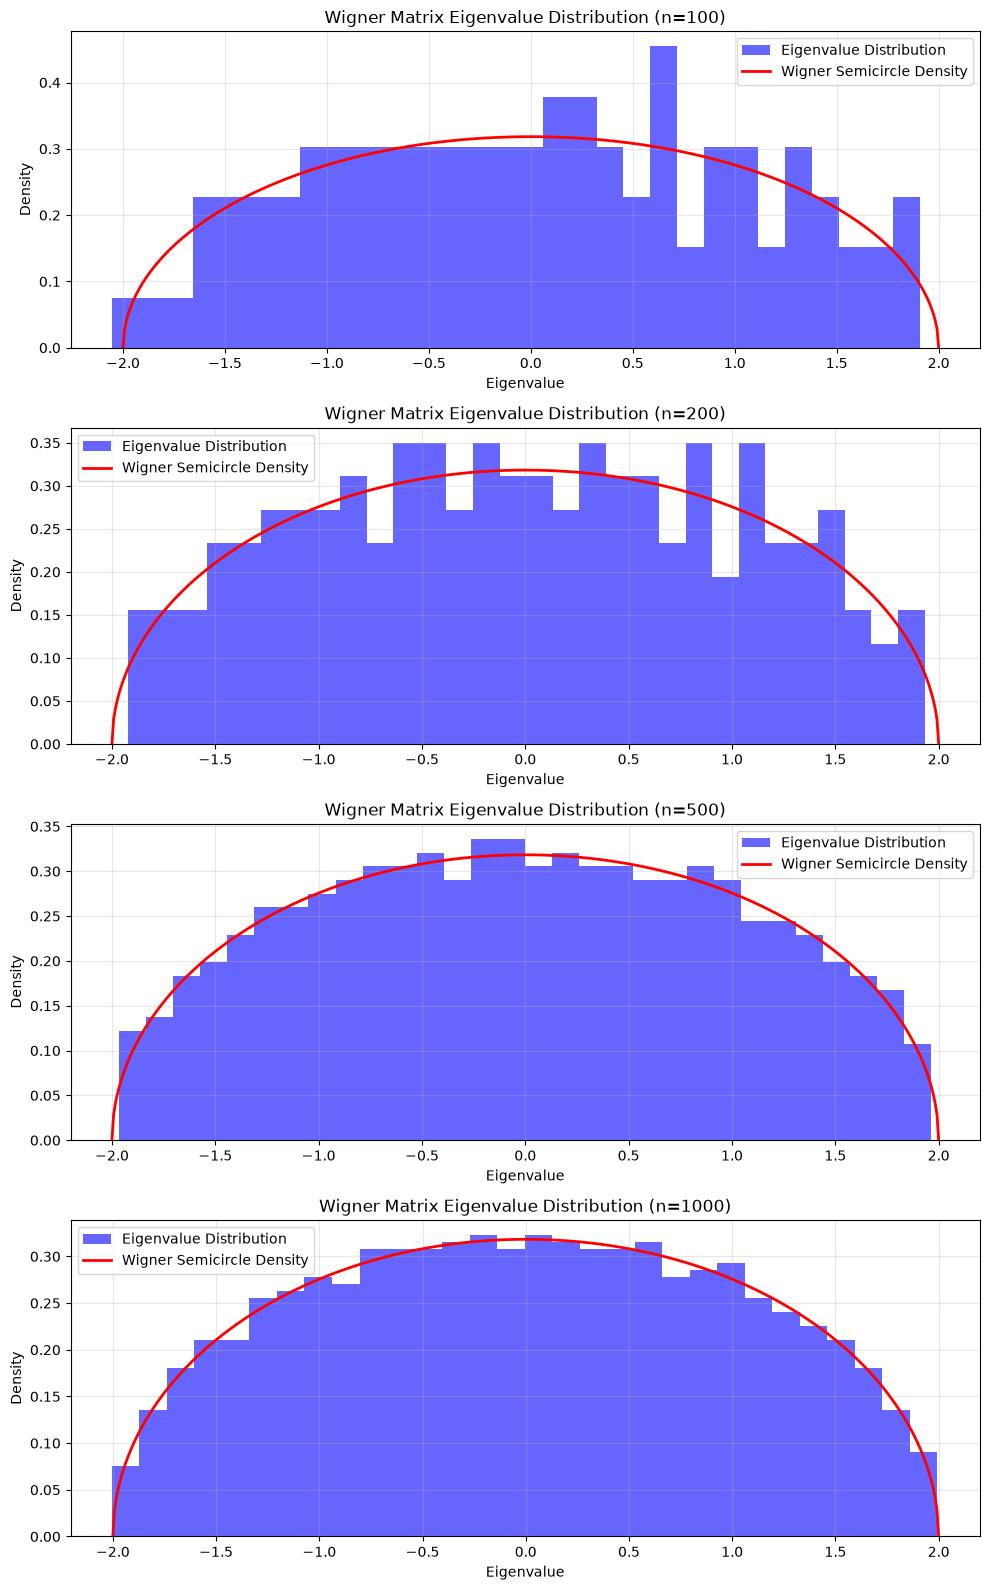

In [9]:
# 设置随机种子，方便复现实验
np.random.seed(42)

# 四种矩阵阶数
n_values = [100, 200, 500, 1000]

# 创建四个纵向排列的子图
fig, axes = plt.subplots(4, 1, figsize=(10, 16))

# 生成半圆密度曲线的数据
x = np.linspace(-2, 2, 500)
y = np.array([wigner_density(i) for i in x])

for ax, n in zip(axes, n_values):

    # 生成 Wigner 矩阵
    matrix = generate_wigner(n)

    # 计算特征值
    eigenvalues = get_spectrum(matrix)

    # 绘制标准化直方图
    ax.hist(
        eigenvalues,
        bins=30,
        density=True,
        color='blue',
        alpha=0.6,
        label='Eigenvalue Distribution'
    )

    # 绘制半圆密度曲线
    ax.plot(
        x,
        y,
        color='red',
        linewidth=2,
        label='Wigner Semicircle Density'
    )

    ax.set_title(f'Wigner Matrix Eigenvalue Distribution (n={n})')
    ax.set_xlabel('Eigenvalue')
    ax.set_ylabel('Density')
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

当矩阵阶数达到约 500 时，半圆密度已经能够较好地拟合特征值分布。

In [10]:
def is_valid_board(board):
    if not isinstance(board, np.ndarray):
        return False

    if board.ndim != 2:
        return False

    if not np.all((board == 0) | (board == 1)):
        return False

    return True

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [12]:
# 测试1：合法的二维棋盘
board1 = np.array([
    [0, 1, 0],
    [1, 1, 0],
    [0, 0, 1]
])

# 测试2：包含非法元素
board2 = np.array([
    [0, 1, 2],
    [1, 0, 1]
])

# 测试3：一维数组
board3 = np.array([0, 1, 0, 1])

# 测试4：合法的全零棋盘
board4 = np.zeros((3, 3), dtype=int)

print("测试1：", is_valid_board(board1))
print("测试2：", is_valid_board(board2))
print("测试3：", is_valid_board(board3))
print("测试4：", is_valid_board(board4))

测试1： True
测试2： False
测试3： False
测试4： True


In [13]:
def gol_step(board):
    if not is_valid_board(board):
        raise ValueError("输入的棋盘不合法")

    # 计算每个细胞周围的活细胞数量
    neighbors = np.zeros(board.shape, dtype=int)

    for i in range(-1, 2):
        for j in range(-1, 2):
            if i == 0 and j == 0:
                continue

            neighbors += np.roll(
                np.roll(board, i, axis=0),
                j,
                axis=1
            )

    # 根据生命游戏规则更新棋盘
    new_board = (
        ((board == 1) & ((neighbors == 2) | (neighbors == 3))) |
        ((board == 0) & (neighbors == 3))
    )

    return new_board.astype(int)

In [14]:
# 创建一个测试棋盘
test_board = np.array([
    [0, 1, 0, 0, 0],
    [0, 0, 1, 0, 0],
    [1, 1, 1, 0, 0],
    [0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0]
])

print("原始棋盘：")
print(test_board)

next_board = gol_step(test_board)

print("\n更新后的棋盘：")
print(next_board)

print("\n棋盘形状是否保持不变：", next_board.shape == test_board.shape)
print("更新后的棋盘是否合法：", is_valid_board(next_board))

原始棋盘：
[[0 1 0 0 0]
 [0 0 1 0 0]
 [1 1 1 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]]

更新后的棋盘：
[[0 0 0 0 0]
 [1 0 1 0 0]
 [0 1 1 0 0]
 [0 1 0 0 0]
 [0 0 0 0 0]]

棋盘形状是否保持不变： True
更新后的棋盘是否合法： True


In [15]:
def draw_gol_board(board):
    if not is_valid_board(board):
        raise ValueError("输入的棋盘不合法")

    plt.figure(figsize=(6, 6))

    # 绘制棋盘：0为白色，1为黑色
    plt.imshow(board, cmap='gray_r', vmin=0, vmax=1)

    # 隐藏坐标轴和刻度
    plt.xticks([])
    plt.yticks([])
    plt.axis('off')

    plt.show()

原始棋盘：


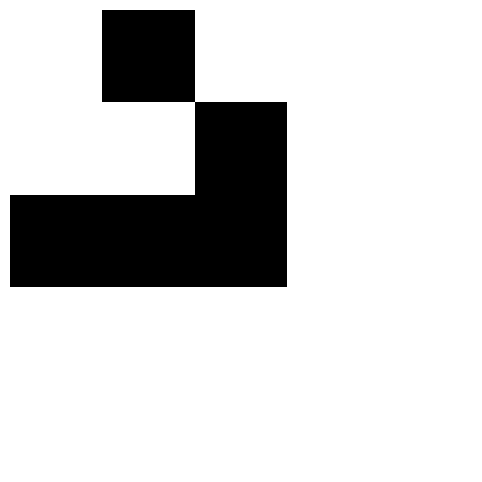

更新后的棋盘：


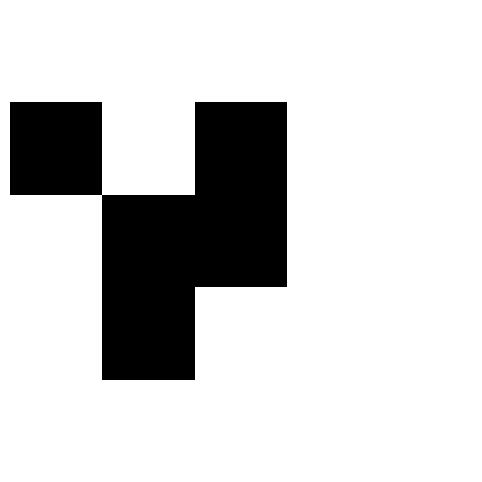

In [16]:
print("原始棋盘：")
draw_gol_board(test_board)

print("更新后的棋盘：")
draw_gol_board(next_board)

In [17]:
import pandas as pd

df = pd.read_csv("Iris.csv")

print("数据读取成功！")
print("数据行数：", len(df))
display(df.head())

数据读取成功！
数据行数： 150


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [18]:
# 修正第35行数据（索引34）
df.loc[34, 'SepalLengthCm'] = 4.9
df.loc[34, 'SepalWidthCm'] = 3.1
df.loc[34, 'PetalLengthCm'] = 1.5
df.loc[34, 'PetalWidthCm'] = 0.2

# 修正第38行数据（索引37）
df.loc[37, 'SepalLengthCm'] = 4.9
df.loc[37, 'SepalWidthCm'] = 3.6
df.loc[37, 'PetalLengthCm'] = 1.4
df.loc[37, 'PetalWidthCm'] = 0.1

# 查看修改结果
print("修改后的第35行和第38行：")
display(df.iloc[[34, 37]])

修改后的第35行和第38行：


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
34,35,4.9,3.1,1.5,0.2,Iris-setosa
37,38,4.9,3.6,1.4,0.1,Iris-setosa


In [19]:
# 添加花瓣长宽比
df['Petal.Ratio'] = df['PetalLengthCm'] / df['PetalWidthCm']

# 添加花萼长宽比
df['Sepal.Ratio'] = df['SepalLengthCm'] / df['SepalWidthCm']

# 查看新增列
print("添加比例列后的数据：")
display(df.head())

# 查看新增列的计算结果
display(df[['Petal.Ratio', 'Sepal.Ratio']].head())

添加比例列后的数据：


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species,Petal.Ratio,Sepal.Ratio
0,1,5.1,3.5,1.4,0.2,Iris-setosa,7.0,1.457143
1,2,4.9,3.0,1.4,0.2,Iris-setosa,7.0,1.633333
2,3,4.7,3.2,1.3,0.2,Iris-setosa,6.5,1.468750
3,4,4.6,3.1,1.5,0.2,Iris-setosa,7.5,1.483871
4,5,5.0,3.6,1.4,0.2,Iris-setosa,7.0,1.388889


,Petal.Ratio,Sepal.Ratio
0,7.0,1.457143
1,7.0,1.633333
2,6.5,1.468750
3,7.5,1.483871
4,7.0,1.388889


In [20]:
# 保存修正后的数据集
df.to_csv("iris_corrected.csv", index=False, encoding="utf-8-sig")

print("文件保存成功！")
print("文件名：iris_corrected.csv")

文件保存成功！
文件名：iris_corrected.csv


In [21]:
# 按花卉种类分组，统计各数值列的平均值、中位数、最小值、最大值和标准差
result = df.groupby('Species').agg({
    'Petal.Ratio': ['mean', 'median', 'min', 'max', 'std'],
    'Sepal.Ratio': ['mean', 'median', 'min', 'max', 'std']
})

print("不同花卉种类的分组统计结果：")
display(result)

不同花卉种类的分组统计结果：


Petal.Ratio                                     Sepal.Ratio  \
                       mean    median       min   max       std        mean   
Species                                                                       
Iris-setosa        6.908000  7.000000  2.666667  15.0  2.854545    1.470188   
Iris-versicolor    3.242837  3.240385  2.666667   4.1  0.312456    2.160402   
Iris-virginica     2.780662  2.666667  2.125000   4.0  0.407367    2.230453   

                                                         
                   median       min       max       std  
Species                                                  
Iris-setosa      1.463063  1.268293  1.956522  0.118750  
Iris-versicolor  2.161290  1.764706  2.818182  0.228658  
Iris-virginica   2.169540  1.823529  2.961538  0.246992